In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

Shape: (512, 512) | dtype: uint8 | min/max: 0 255


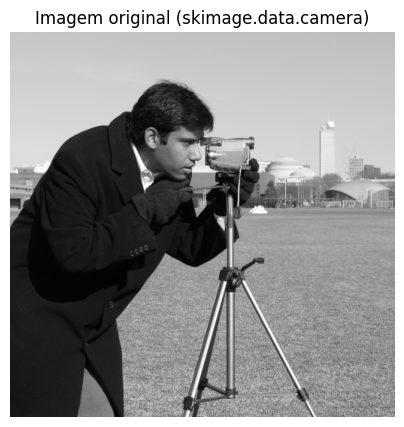

In [2]:
imagem = data.camera()   # já é grayscale, uint8, 512x512
print("Shape:", imagem.shape, "| dtype:", imagem.dtype, "| min/max:", imagem.min(), imagem.max())

plt.figure(figsize=(5, 5))
plt.imshow(imagem, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem original (skimage.data.camera)")
plt.axis("off")
plt.show()

In [3]:
def preencher_bordas(imagem, pad):
    h, w = imagem.shape
    padded = np.zeros((h + 2 * pad, w + 2 * pad), dtype=imagem.dtype)
    padded[pad:pad + h, pad:pad + w] = imagem
    padded[:pad, pad:pad + w] = imagem[0, :]            # topo
    padded[pad + h:, pad:pad + w] = imagem[-1, :]       # base
    padded[:, :pad] = padded[:, pad:pad + 1]            # esquerda
    padded[:, pad + w:] = padded[:, pad + w - 1:pad + w]  # direita
    return padded


def convolucao_manual(imagem, kernel):
    kh, kw = kernel.shape
    pad = kh // 2
    kernel_espelhado = kernel[::-1, ::-1]   # definição de convolução
    padded = preencher_bordas(imagem, pad).astype(np.float64)
    h, w = imagem.shape
    saida = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            regiao = padded[i:i + kh, j:j + kw]
            saida[i, j] = np.sum(regiao * kernel_espelhado)
    return saida


def convolucao_janela(imagem, tamanho, operacao):
    pad = tamanho // 2
    padded = preencher_bordas(imagem, pad)
    h, w = imagem.shape
    saida = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            janela = padded[i:i + tamanho, j:j + tamanho]
            saida[i, j] = operacao(janela)
    return saida

In [4]:
def filtro_media(imagem, tamanho=3):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    resultado = convolucao_manual(imagem, kernel)
    return np.clip(np.round(resultado), 0, 255).astype(np.uint8)


def filtro_mediana(imagem, tamanho=3):
    def mediana(janela):
        valores = np.sort(janela.ravel())
        return valores[len(valores) // 2]
    return convolucao_janela(imagem, tamanho, mediana).astype(np.uint8)


def filtro_moda(imagem, tamanho=3):
    def moda(janela):
        contagem = np.bincount(janela.ravel(), minlength=256)
        return np.argmax(contagem)   # em empate, escolhe o menor valor
    return convolucao_janela(imagem, tamanho, moda).astype(np.uint8)


def filtro_maxima(imagem, tamanho=3):
    def maximo(janela):
        m = janela[0, 0]
        for v in janela.ravel():
            if v > m:
                m = v
        return m
    return convolucao_janela(imagem, tamanho, maximo).astype(np.uint8)

In [5]:
TAMANHO = 5

img_media   = filtro_media(imagem, TAMANHO)
img_mediana = filtro_mediana(imagem, TAMANHO)
img_moda    = filtro_moda(imagem, TAMANHO)
img_maxima  = filtro_maxima(imagem, TAMANHO)

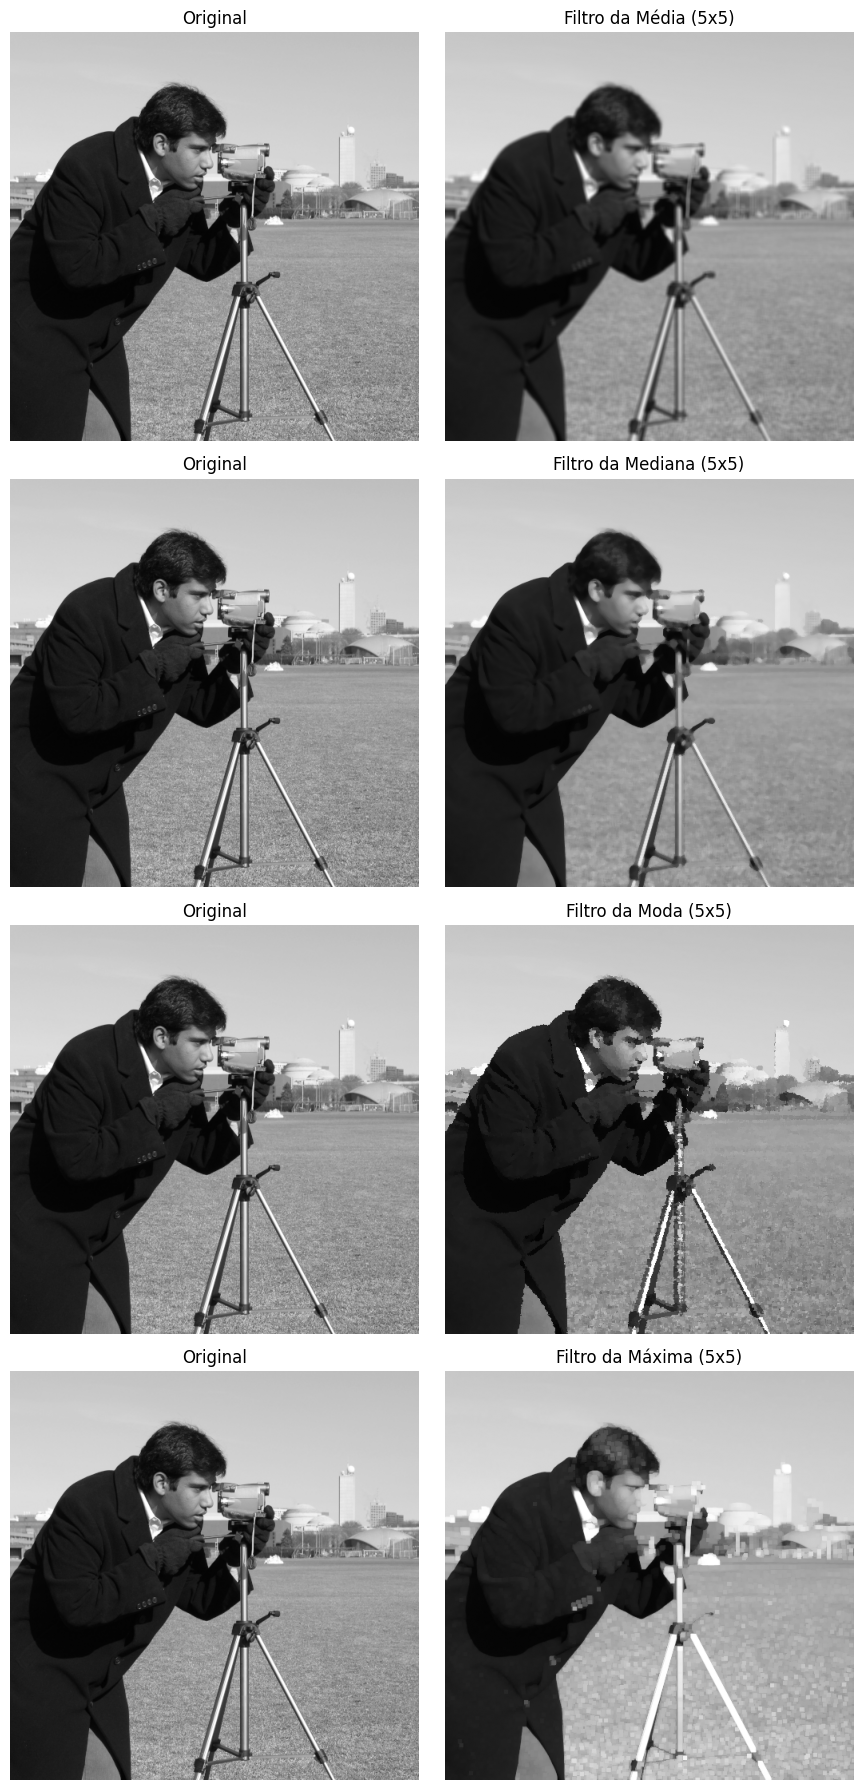

In [6]:
resultados = [
    ("Média",   img_media),
    ("Mediana", img_mediana),
    ("Moda",    img_moda),
    ("Máxima",  img_maxima),
]

fig, axes = plt.subplots(4, 2, figsize=(9, 18))
for linha, (nome, filtrada) in enumerate(resultados):
    axes[linha, 0].imshow(imagem, cmap="gray", vmin=0, vmax=255)
    axes[linha, 0].set_title("Original")
    axes[linha, 1].imshow(filtrada, cmap="gray", vmin=0, vmax=255)
    axes[linha, 1].set_title(f"Filtro da {nome} ({TAMANHO}x{TAMANHO})")
    for ax in axes[linha]:
        ax.axis("off")
plt.tight_layout()
plt.show()

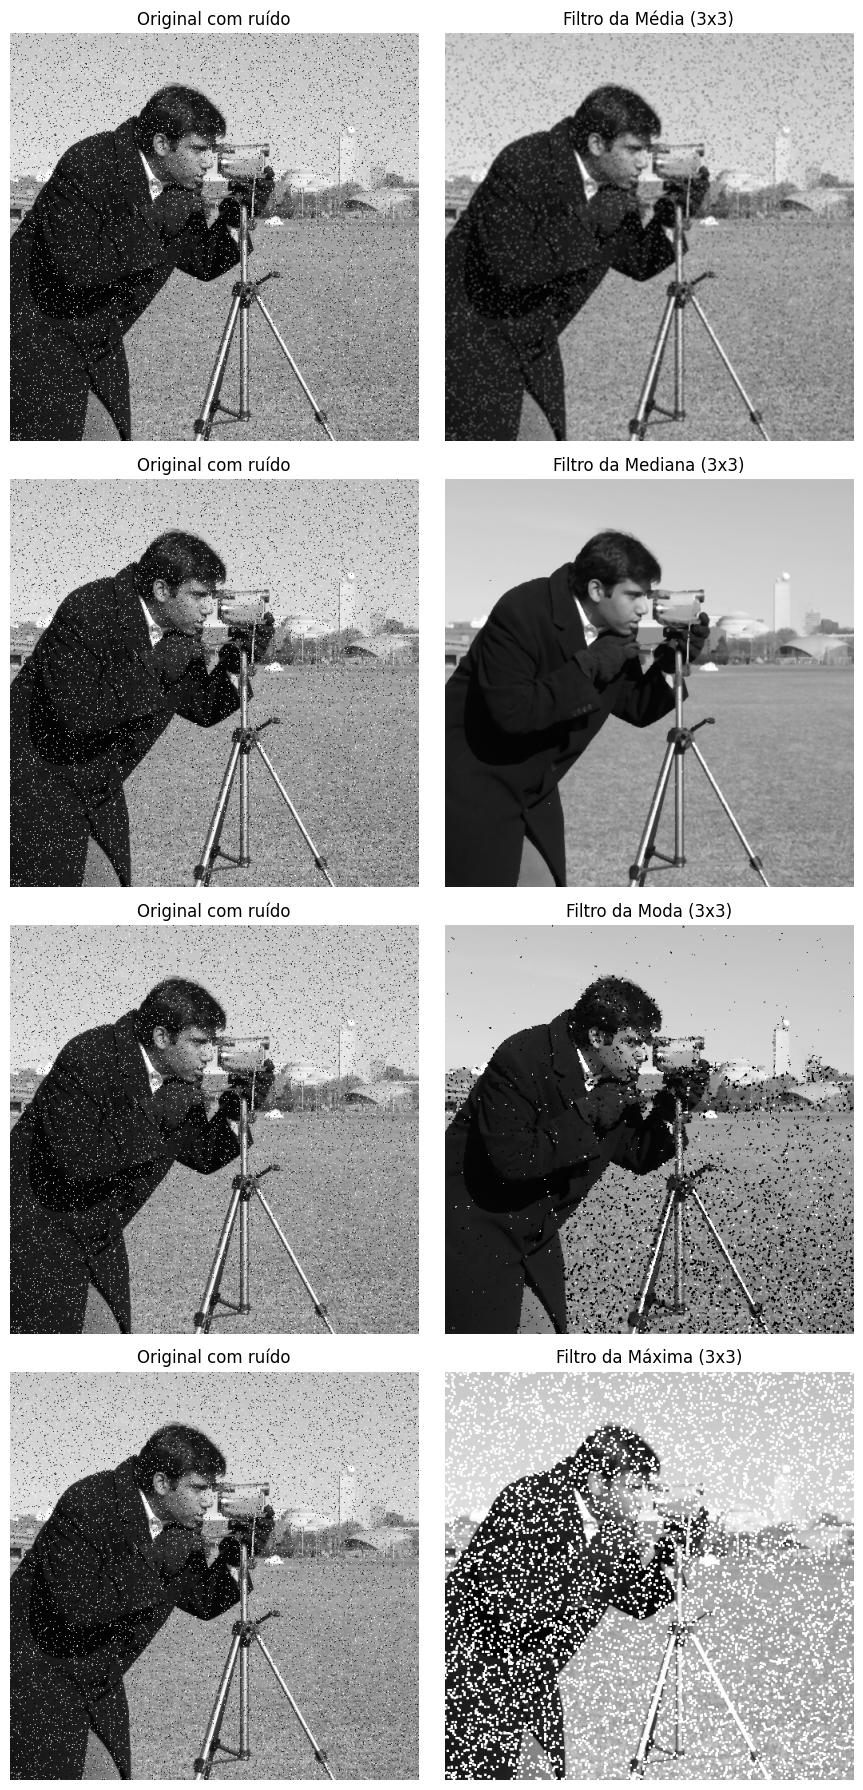

In [7]:
rng = np.random.default_rng(42)
ruidosa = imagem.copy()
mascara = rng.random(imagem.shape)
ruidosa[mascara < 0.03] = 0
ruidosa[mascara > 0.97] = 255

filtros = [("Média", filtro_media), ("Mediana", filtro_mediana),
           ("Moda", filtro_moda), ("Máxima", filtro_maxima)]

fig, axes = plt.subplots(4, 2, figsize=(9, 18))
for linha, (nome, f) in enumerate(filtros):
    axes[linha, 0].imshow(ruidosa, cmap="gray", vmin=0, vmax=255)
    axes[linha, 0].set_title("Original com ruído")
    axes[linha, 1].imshow(f(ruidosa, 3), cmap="gray", vmin=0, vmax=255)
    axes[linha, 1].set_title(f"Filtro da {nome} (3x3)")
    for ax in axes[linha]:
        ax.axis("off")
plt.tight_layout()
plt.show()